# **reconaissance voyelle**

In [1]:
import numpy as np
import msicpe.mana as mana
import msicpe.san as san
import pandas as pd
import msicpe.san as san
from plotly import express as px
import matplotlib.pyplot as plt
import scipy as signal

In [2]:
signal_dict = np.load('data partie 2/apprentissage/o_2.npz') # signal_dict est un dictionnaire
s = signal_dict['s'] # extraction du signal utile
t = signal_dict['t']        

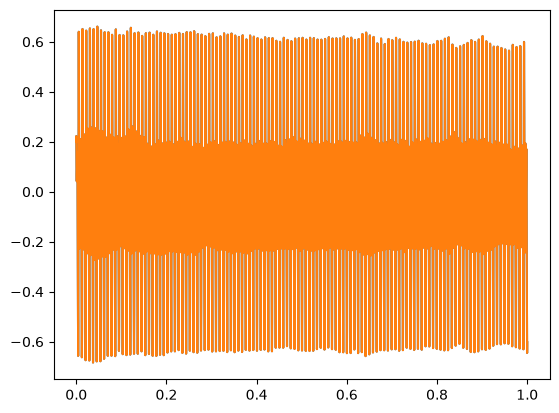

In [3]:
s_centre = s - np.mean(s)
plt.plot(t,s)
plt.plot(t,s_centre)

In [4]:
nu, S = san.trans_fourier(s_centre, t)

spectre = np.abs(S)

df = pd.DataFrame({"nu": nu, "spectre": spectre})

fig = px.line(
    df, 
    x="nu", 
    y=["spectre"], 
    title="Courbe de la fonction"
)
fig.show()

#plt.plot(nu, spectre)

/Users/adel/Documents/code/env_cpe/lib/python3.12/site-packages/matplotlib/cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/adel/Documents/code/env_cpe/lib/python3.12/site-packages/matplotlib/cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


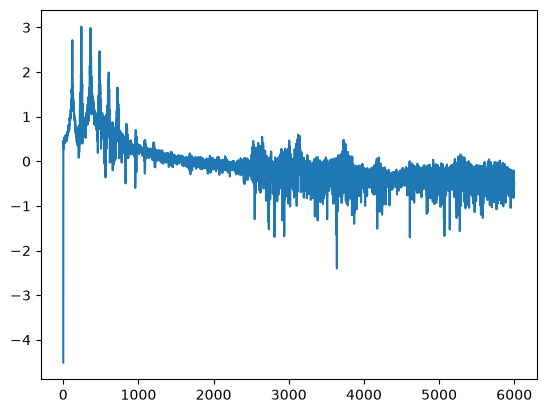

In [5]:
plt.plot(nu, np.log10(S))

In [6]:
help(san.detect_fondamentale)
spectre_norm = spectre/np.max(spectre)

fond = san.detect_fondamentale(spectre_norm,nu)
print(fond)
print(spectre[134])

Help on function detect_fondamentale in module msicpe.san.detect_fondamentale:

detect_fondamentale(spectre, nu, threshold=0.25)
    Fonction permettant de déterminer la fréquence fondamentale d'un signal à partir de son spectre.
    Args:
        spectre (ndarray): spectre du signal
        nu (ndarray): vecteur des fréquences associées au spectre
        threshold (float, optional): seuil pour la détection de la fréquence fondamentale. Default à 0.25.
    Returns:
        nu_fond (float): fréquence fondamentale détectée en Hz

120.95967002777779
13.630949


In [7]:
def vect_signal(chemin, H):
    dat = np.load(chemin)
    s = dat['s']
    t = dat['t']

    s = s - np.mean(s) # centrage du signal

    # Calcul du spectre et normalisation
    nu, sig = san.trans_fourier(s, t)
    spectre = np.abs(sig)
    spectre_norm = spectre / np.max(spectre)

    # Détection de f0
    f0 = san.detect_fondamentale(spectre_norm, nu)

    # Création de la liste des H + 1 fréquences : [f0, 2*f0, ..., (H+1)*f0]
    freq_list = [k * f0 for k in range(1, H + 2)]

    # Extraction des amplitudes des pics
    _, peak_amplitudes = san.detect_pics(spectre_norm, freq_list, nu)

    # Renvoi du vecteur caractéristique en échelle logarithmique (taille H + 1)
    return np.log10(peak_amplitudes)

print(vect_signal('/Users/adel/Documents/code/SAN/Projet SAN/data partie 2/etude/BON_signal_3.npz',11))

[-0.12075384  0.         -1.4711585  -2.3327425  -2.80172    -2.4447694
 -2.6249788  -2.8398972  -2.854561   -2.8098037  -2.9446673  -3.0266018 ]


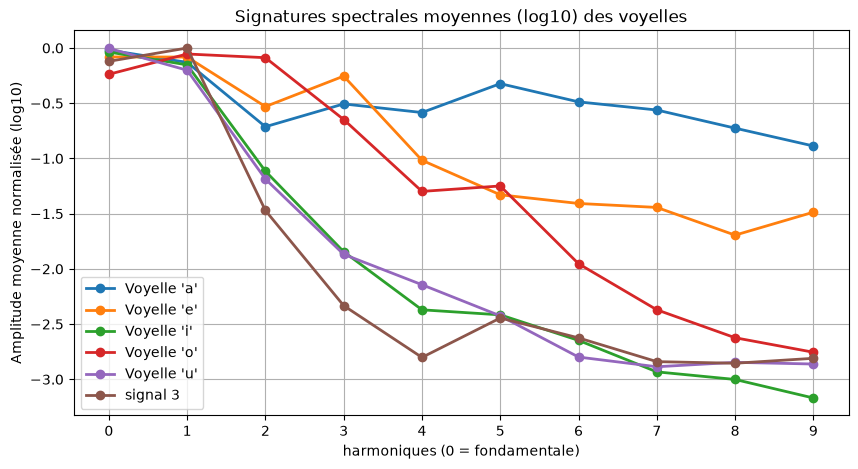

In [160]:
voyelles = ['a', 'e', 'i', 'o', 'u']
H = 9  # Nombre d'harmoniques (vecteur final de dimension H + 1)
nb_sons = 5

dico_vects = {}
harmoniques = np.arange(0, H + 1)

plt.figure(figsize=(10, 5))

for v in voyelles:
    vecteurs = np.zeros((nb_sons, H + 1))

    for i in range(1, nb_sons + 1):

        # Stockage en échelle logarithmique (base 10)
        vecteurs[i - 1, :] = vect_signal(f'data partie 2/apprentissage/{v}_{i}.npz',H)

    # Calcul et sauvegarde du vecteur moyen pour la voyelle v
    dico_vects[v] = np.mean(vecteurs, axis=0)

    # Tracé du vecteur moyen
    plt.plot(
        harmoniques,
        dico_vects[v],
        '-o',
        linewidth=2,
        label=f"Voyelle '{v}'",
    )

#plot du signal d'etude 3
plt.plot(
        harmoniques,
        vect_signal('data partie 2/etude/BON_signal_3.npz',H),
        '-o',
        linewidth=2,
        label="signal 3",
    )

plt.title('Signatures spectrales moyennes (log10) des voyelles')
plt.xlabel('harmoniques (0 = fondamentale)')
plt.ylabel('Amplitude moyenne normalisée (log10)')
plt.xticks(harmoniques)
plt.grid(True)
plt.legend()
plt.show()

In [161]:
distances_v =[]
vect_test = vect_signal('data partie 2/test/a_6.npz',H)
for v in voyelles :
    distance = 0
    for i in range(len(vect_test)) :
        distance += np.abs(vect_test[i]-dico_vects[v][i])
    distances_v.append(float(distance))

print(distances_v)
print(dico_vects.keys())
    


[1.9447536367923024, 5.710641079876222, 16.071087154746056, 10.544784344546496, 15.604878160543738]
dict_keys(['a', 'e', 'i', 'o', 'u'])


In [162]:
def test_signal(chemin,H,dico_vect,print_dist) :
    distances_v =[]
    voyelles = list(dico_vects.keys())
    indice_bonne_lettre = 0
    equidistance = False

    vect_test = vect_signal(chemin,H)

    for v in voyelles :
        distance = 0
        for i in range(len(vect_test)) :
            distance += np.abs(vect_test[i]-dico_vects[v][i])
        distances_v.append(float(distance))

    for i in range(len(distances_v)) :
        if distances_v[i] == np.min(distances_v) and equidistance == False :
            indice_bonne_lettre = i
            equidistance = True
        
        elif distances_v[i] == np.min(distances_v) and equidistance == True :
            return test_signal(chemin,H+1,dico_vect,print_dist)
        

    if print_dist :
        for i in range(len(distances_v))  :
            print("distance de ", voyelles[i], ":", distances_v[i])

    return "la voyelle plus proche est : "+ voyelles[indice_bonne_lettre]

In [163]:
print(test_signal('data partie 2/etude/BON_signal_3.npz',H,dico_vects,True))



#Test sur tous les signaux de la base test : 
# for v in voyelles :
#     for i in range(2) :
#         print("TEST pour",v,"_",i+6)
#         print(test_signal(f'data partie 2/test/{v}_{i+6}.npz',H,dico_vects,False))


distance de  a : 15.62281296364963
distance de  e : 11.137934037778177
distance de  i : 2.161319342255592
distance de  o : 7.365621325932444
distance de  u : 2.025551596097648
la voyelle plus proche est : u


In [164]:
vo = list(dico_vects.keys())
print(vo)

i = "a"
val = 5
print("la valeur est", val, "et la lettre :", i)


ls = [1,3,4,65,99]
print(np.min(ls))
#for i in range(len(ls)) :
    #print(ls[i])

['a', 'e', 'i', 'o', 'u']
la valeur est 5 et la lettre : a
1
